# Tổng hợp kết quả mô hình - Phần của Hùng
Notebook này đọc `report/model_comparison.csv`, kiểm tra 4 kết quả Decision Tree A/B và K-NN A/B, sau đó hỗ trợ so sánh Accuracy, Recall và F1-score.

**Không điền số giả. Chỉ chạy phần phân tích sau khi Đức và Hải gửi kết quả thật.**

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
REPORT_CSV = Path('../report/model_comparison.csv')
df = pd.read_csv(REPORT_CSV)
df


,model_id,member,model,flow,accuracy,precision,recall,f1_score,confusion_matrix
0,decision_tree_A,Đức,Decision Tree,A,0.748758,0.517483,0.791444,0.625793,"[[759, 276], [78, 296]]"
1,decision_tree_B,Đức,Decision Tree,B,0.734564,0.500000,0.799465,0.615226,"[[736, 299], [75, 299]]"
2,knn_A,Hải,K-NN,A,0.786373,0.596817,0.601604,0.599201,"[[883, 152], [149, 225]]"
3,knn_B,Hải,K-NN,B,0.790632,0.623824,0.532086,0.574315,"[[915, 120], [175, 199]]"


In [3]:
metric_cols = ['accuracy', 'precision', 'recall', 'f1_score']
missing = df[metric_cols].isna().sum()
print('Số giá trị còn thiếu:')
print(missing)

if df[metric_cols].isna().any().any():
    print('\nChưa đủ kết quả thật từ Đức và Hải. Chưa nên kết luận mô hình.')
else:
    print('\nĐã đủ 4 kết quả để phân tích.')


Số giá trị còn thiếu:
accuracy     0
precision    0
recall       0
f1_score     0
dtype: int64

Đã đủ 4 kết quả để phân tích.


In [4]:
if not df[metric_cols].isna().any().any():
    bang_so_sanh = df[['model', 'flow'] + metric_cols].copy()
    bang_so_sanh = bang_so_sanh.sort_values('f1_score', ascending=False)
    display(bang_so_sanh)


,model,flow,accuracy,precision,recall,f1_score
0,Decision Tree,A,0.748758,0.517483,0.791444,0.625793
1,Decision Tree,B,0.734564,0.500000,0.799465,0.615226
2,K-NN,A,0.786373,0.596817,0.601604,0.599201
3,K-NN,B,0.790632,0.623824,0.532086,0.574315


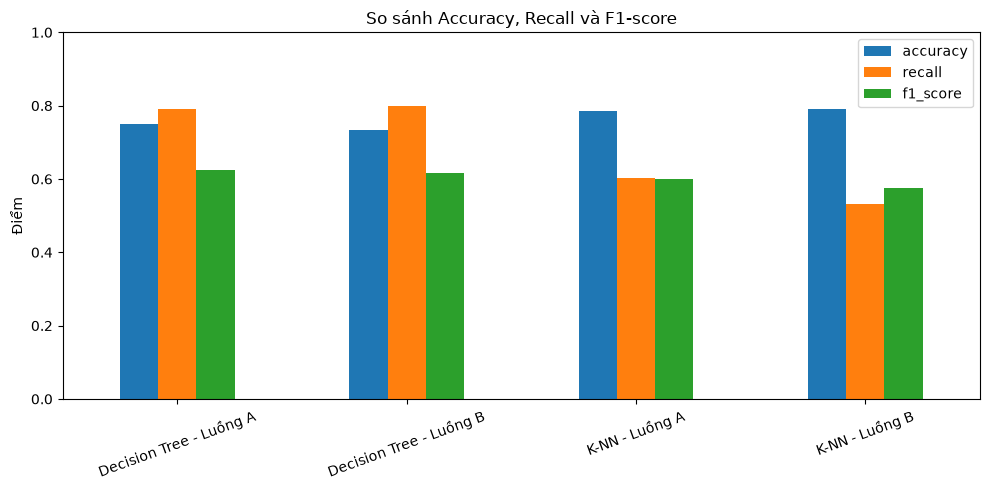

In [5]:
if not df[metric_cols].isna().any().any():
    labels = df['model'] + ' - Luồng ' + df['flow']
    ax = df.set_index(labels)[['accuracy', 'recall', 'f1_score']].plot(kind='bar', figsize=(10, 5))
    ax.set_ylim(0, 1)
    ax.set_ylabel('Điểm')
    ax.set_title('So sánh Accuracy, Recall và F1-score')
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()


## Gợi ý viết phần thảo luận
- So sánh cùng một thuật toán giữa Luồng A và Luồng B.
- So sánh Decision Tree và K-NN trên cùng một luồng.
- Không chỉ nhìn Accuracy; chú ý Recall và F1-score của lớp Churn.
- Đối chiếu Confusion Matrix để xem mô hình bỏ sót bao nhiêu khách hàng thực sự rời bỏ.
